# Wetteranalyse Berlin

Dieses Notebook untersucht historische Tageswerte für Berlin im Kalenderjahr 2025. Wir betrachten Mitteltemperatur, Niederschlag und maximale Windgeschwindigkeit, bereinigen fehlende Werte und suchen besonders warme, kalte, nasse und windige Tage.

Die Daten kommen von der frei zugänglichen [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api). Koordinaten: 52.52° N, 13.405° E; Zeitzone: Europe/Berlin. Die Analyse ist beschreibend und ersetzt keine Klimanormalwerte oder Wettervorhersage.

## 1. Benötigte Bibliotheken importieren

Pandas verwaltet die Wettertabelle, NumPy unterstützt numerische Prüfungen und Matplotlib erstellt die Diagramme. Führe die folgende Installationszelle bei Bedarf einmal aus. Anschließend importierst du die Bibliotheken.

In [9]:
%pip install pandas numpy matplotlib

import json
from urllib.parse import urlencode
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

Note: you may need to restart the kernel to use updated packages.


## 2. Wetterdaten für Berlin laden

Wir holen tägliche Beobachtungswerte für das gesamte Jahr 2025 direkt von Open-Meteo. Die API liefert Mitteltemperatur in °C, Niederschlag in mm und maximale Windgeschwindigkeit in km/h. Für den Abruf ist eine Internetverbindung erforderlich.

In [10]:
parameter = {
    "latitude": 52.52,
    "longitude": 13.405,
    "start_date": "2025-01-01",
    "end_date": "2025-12-31",
    "daily": "temperature_2m_mean,precipitation_sum,wind_speed_10m_max",
    "timezone": "Europe/Berlin",
}
api_url = "https://archive-api.open-meteo.com/v1/archive?" + urlencode(parameter)

with urlopen(api_url, timeout=30) as antwort:
    wetter_json = json.load(antwort)

tageswerte = wetter_json["daily"]
wetter = pd.DataFrame(
    {
        "temperatur_mittel_c": tageswerte["temperature_2m_mean"],
        "niederschlag_mm": tageswerte["precipitation_sum"],
        "wind_max_kmh": tageswerte["wind_speed_10m_max"],
    },
    index=pd.to_datetime(tageswerte["time"]),
)
wetter.index.name = "datum"
wetter = wetter.sort_index()

assert len(wetter) == 365, f"Erwartet: 365 Tage, erhalten: {len(wetter)}"
wetter.head()

,temperatur_mittel_c,niederschlag_mm,wind_max_kmh
datum,,,
2025-01-01,4.8,0.1,26.4
2025-01-02,4.0,4.1,26.1
2025-01-03,0.8,3.1,30.3
2025-01-04,-1.1,0.0,19.8
2025-01-05,-1.0,9.3,18.7


## 3. Erste Datenexploration und -bereinigung

Prüfe zuerst Tabellenstruktur und fehlende Werte. Nicht-endliche Zahlen werden als fehlend markiert; Tage ohne vollständige Messwerte für alle drei Größen werden für die folgende Auswertung ausgeschlossen. Die Anzahl entfernter Tage wird ausgegeben.

In [11]:
print(f"Datenumfang vor Bereinigung: {wetter.shape[0]} Tage, {wetter.shape[1]} Messgrößen")
display(wetter.head())

wetter = wetter.replace([np.inf, -np.inf], np.nan)
fehlwerte = wetter.isna().sum().rename("fehlende Werte")
display(fehlwerte.to_frame())

tage_vorher = len(wetter)
wetter = wetter.dropna()
print(f"Entfernte Tage mit fehlenden Werten: {tage_vorher - len(wetter)}")
display(wetter.describe().round(2))

Datenumfang vor Bereinigung: 365 Tage, 3 Messgrößen


,temperatur_mittel_c,niederschlag_mm,wind_max_kmh
datum,,,
2025-01-01,4.8,0.1,26.4
2025-01-02,4.0,4.1,26.1
2025-01-03,0.8,3.1,30.3
2025-01-04,-1.1,0.0,19.8
2025-01-05,-1.0,9.3,18.7


,fehlende Werte
temperatur_mittel_c,0
niederschlag_mm,0
wind_max_kmh,0


Entfernte Tage mit fehlenden Werten: 0


,temperatur_mittel_c,niederschlag_mm,wind_max_kmh
count,365.00,365.00,365.00
mean,10.65,1.67,15.49
std,7.45,3.84,5.16
min,-7.40,0.00,5.10
25%,4.80,0.00,11.60
50%,10.80,0.10,15.20
75%,17.10,1.70,18.70
max,29.90,44.80,33.20


## 4. Zeitreihenanalyse: Temperaturverlauf

Das Liniendiagramm zeigt die tägliche Mitteltemperatur. Eine gleitende 30-Tage-Mittelung glättet kurzfristige Schwankungen und macht den saisonalen Verlauf leichter sichtbar.

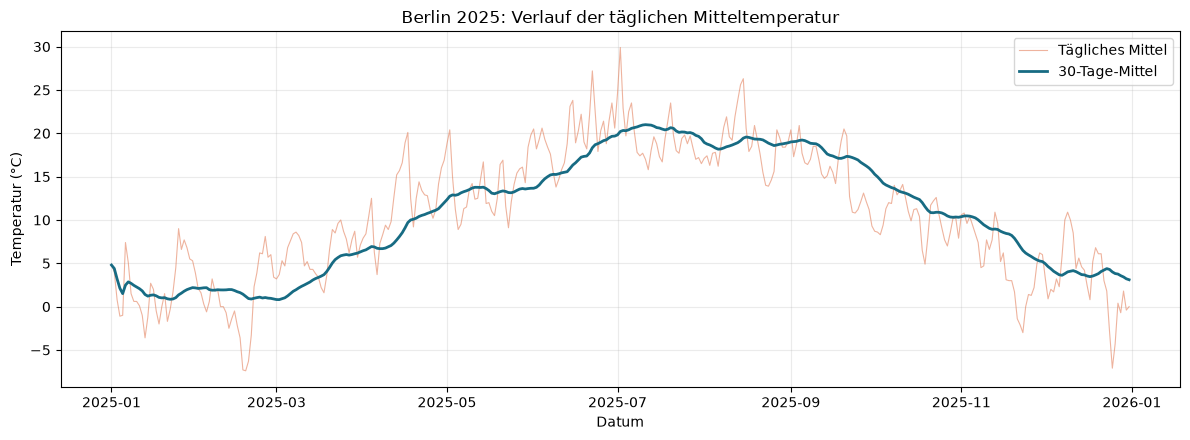

In [12]:
temperatur_30_tage = wetter["temperatur_mittel_c"].rolling(window=30, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(wetter.index, wetter["temperatur_mittel_c"], color="#e1764f", linewidth=0.8, alpha=0.55, label="Tägliches Mittel")
ax.plot(wetter.index, temperatur_30_tage, color="#176b83", linewidth=2, label="30-Tage-Mittel")
ax.set_title("Berlin 2025: Verlauf der täglichen Mitteltemperatur")
ax.set_xlabel("Datum")
ax.set_ylabel("Temperatur (°C)")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## 5. Visualisierung von Niederschlagsdaten

Für den Überblick addieren wir die Tagesniederschläge zu Monatssummen. So lassen sich die niederschlagsreichsten und trockensten Monate vergleichen.

,Niederschlag (mm)
datum,
2025-01-01,82.5
2025-02-01,22.3
2025-03-01,13.5
2025-04-01,15.8
2025-05-01,24.5
2025-06-01,48.6
2025-07-01,185.8
2025-08-01,40.4
2025-09-01,53.9


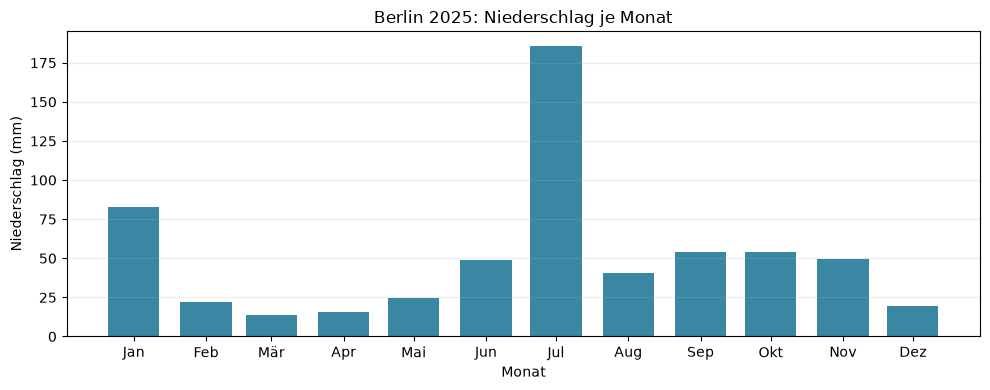

In [13]:
niederschlag_monat = wetter["niederschlag_mm"].resample("MS").sum()
display(niederschlag_monat.rename("Niederschlag (mm)").to_frame().round(1))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(niederschlag_monat.index, niederschlag_monat.values, width=22, color="#3987a3")
ax.set_xticks(niederschlag_monat.index, ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"])
ax.set_title("Berlin 2025: Niederschlag je Monat")
ax.set_xlabel("Monat")
ax.set_ylabel("Niederschlag (mm)")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

## 6. Analyse von Extremwerten

Zum Abschluss finden wir die Tage mit der höchsten und niedrigsten Mitteltemperatur sowie den stärksten Tagesniederschlag und der größten maximalen Windgeschwindigkeit. Die Tabelle zeigt jeweils den Messwert und das zugehörige Datum.

In [14]:
extremtage = pd.DataFrame(
    {
        "Ereignis": [
            "Wärmster Tag (Tagesmittel)",
            "Kältester Tag (Tagesmittel)",
            "Niederschlagsreichster Tag",
            "Windigste Tag (Tagesmaximum)",
        ],
        "Datum": [
            wetter["temperatur_mittel_c"].idxmax(),
            wetter["temperatur_mittel_c"].idxmin(),
            wetter["niederschlag_mm"].idxmax(),
            wetter["wind_max_kmh"].idxmax(),
        ],
        "Messwert": [
            f"{wetter['temperatur_mittel_c'].max():.1f} °C",
            f"{wetter['temperatur_mittel_c'].min():.1f} °C",
            f"{wetter['niederschlag_mm'].max():.1f} mm",
            f"{wetter['wind_max_kmh'].max():.1f} km/h",
        ],
    }
)
display(extremtage)

,Ereignis,Datum,Messwert
0,Wärmster Tag (Tagesmittel),2025-07-02,29.9 °C
1,Kältester Tag (Tagesmittel),2025-02-18,-7.4 °C
2,Niederschlagsreichster Tag,2025-07-21,44.8 mm
3,Windigste Tag (Tagesmaximum),2025-10-26,33.2 km/h


## 7. Vergleich mit DWD-Messdaten

Als Referenz dient die DWD-Station Berlin-Tempelhof (Stations-ID 00433; 52,4676° N, 13,4020° E). Sie liegt etwa 5,8 km vom verwendeten Open-Meteo-Punkt (52,52° N, 13,405° E) entfernt. Der DWD liefert Stationsmessungen, Open-Meteo hier einen räumlichen Rasterwert; Unterschiede können daher sowohl durch den Ort als auch durch die Datenmethode entstehen.

Wir vergleichen Tagesmitteltemperatur und Niederschlag. Die DWD-Tagesniederschläge beziehen sich auf ein Messfenster von 06:00 bis 06:00 UTC, Open-Meteo auf Kalendertage in Europe/Berlin. Deshalb vergleichen wir Niederschlag nur als Monatssumme und interpretieren selbst diese mit Vorsicht. Die DWD-Datei enthält fehlende Messwerte als -999; diese werden beim Laden in fehlende Werte umgewandelt.

Quelle: [DWD Climate Data Center, Tageswerte Berlin-Tempelhof](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/historical/).

In [15]:
import io
import zipfile

dwd_url = "https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/historical/tageswerte_KL_00433_19480101_20251231_hist.zip"
with urlopen(dwd_url, timeout=30) as antwort:
    dwd_zip_daten = antwort.read()

with zipfile.ZipFile(io.BytesIO(dwd_zip_daten)) as archiv:
    dateiname = next(name for name in archiv.namelist() if name.startswith("produkt_klima_tag_") and name.endswith(".txt"))
    dwd_roh = pd.read_csv(
        archiv.open(dateiname),
        sep=";",
        encoding="latin-1",
        skipinitialspace=True,
        na_values=[-999],
    )

dwd_roh.columns = dwd_roh.columns.str.strip()
dwd_roh["datum"] = pd.to_datetime(dwd_roh["MESS_DATUM"].astype(str), format="%Y%m%d")
dwd = (
    dwd_roh.set_index("datum")
    .loc["2025-01-01":"2025-12-31", ["TMK", "RSK"]]
    .rename(columns={"TMK": "temperatur_dwd_c", "RSK": "niederschlag_dwd_mm"})
    .replace([-999, -999.0], np.nan)
    .sort_index()
)

assert len(dwd) == 365, f"Erwartet: 365 DWD-Tage, erhalten: {len(dwd)}"
vergleich = wetter[["temperatur_mittel_c", "niederschlag_mm"]].join(dwd, how="inner")
print(f"Gemeinsame Vergleichstage: {len(vergleich)} von 365")
display(dwd.head())

Gemeinsame Vergleichstage: 365 von 365


,temperatur_dwd_c,niederschlag_dwd_mm
datum,,
2025-01-01,5.5,0.8
2025-01-02,4.6,0.2
2025-01-03,1.4,0.4
2025-01-04,0.0,0.0
2025-01-05,-0.8,10.9


### Temperatur und Niederschlag vergleichen

Für die Temperatur berechnen wir mittlere Abweichung (Open-Meteo minus DWD) und mittleren absoluten Fehler. Eine positive mittlere Abweichung bedeutet, dass Open-Meteo im Mittel höhere Temperaturen angibt. Die Temperaturkurven sind zur besseren Lesbarkeit als 14-Tage-Mittel dargestellt. Beim Niederschlag vergleichen wir Monatssummen, da die DWD-Tagesgrenzen von den lokalen Open-Meteo-Kalendertagen abweichen.

,Wert
Gemeinsame Temperaturtage,365.00
Mittlere Abweichung Open-Meteo minus DWD (°C),-0.45
Mittlerer absoluter Fehler (°C),0.63


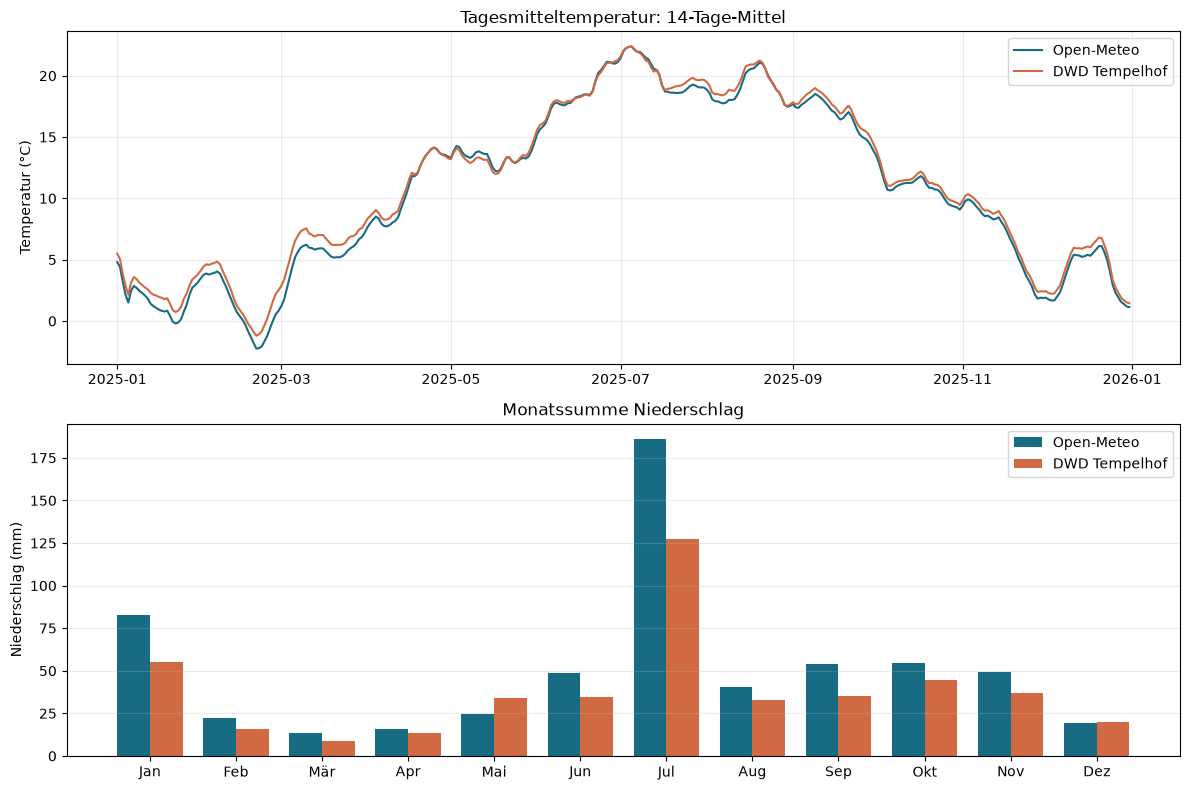

In [16]:
temperatur_paare = vergleich.dropna(subset=["temperatur_mittel_c", "temperatur_dwd_c"])
abweichung_c = temperatur_paare["temperatur_mittel_c"] - temperatur_paare["temperatur_dwd_c"]
kennzahlen = pd.Series(
    {
        "Gemeinsame Temperaturtage": len(temperatur_paare),
        "Mittlere Abweichung Open-Meteo minus DWD (°C)": abweichung_c.mean(),
        "Mittlerer absoluter Fehler (°C)": abweichung_c.abs().mean(),
    },
    name="Wert",
)
display(kennzahlen.to_frame().round(2))

temperatur_vergleich = temperatur_paare[["temperatur_mittel_c", "temperatur_dwd_c"]].rolling(14, min_periods=1).mean()
monatswerte = vergleich[["niederschlag_mm", "niederschlag_dwd_mm"]].resample("MS").agg(["sum", "count"])
tage_pro_monat = monatswerte.index.days_in_month
niederschlag_vergleich = pd.DataFrame(index=monatswerte.index)
for spalte in ["niederschlag_mm", "niederschlag_dwd_mm"]:
    niederschlag_vergleich[spalte] = monatswerte[(spalte, "sum")].where(
        monatswerte[(spalte, "count")] == tage_pro_monat
    )

fig, achsen = plt.subplots(2, 1, figsize=(12, 8))
achsen[0].plot(temperatur_vergleich.index, temperatur_vergleich["temperatur_mittel_c"], label="Open-Meteo", color="#176b83")
achsen[0].plot(temperatur_vergleich.index, temperatur_vergleich["temperatur_dwd_c"], label="DWD Tempelhof", color="#d16a42")
achsen[0].set_title("Tagesmitteltemperatur: 14-Tage-Mittel")
achsen[0].set_ylabel("Temperatur (°C)")
achsen[0].legend()
achsen[0].grid(alpha=0.25)

x = np.arange(len(niederschlag_vergleich))
breite = 0.38
achsen[1].bar(x - breite / 2, niederschlag_vergleich["niederschlag_mm"], breite, label="Open-Meteo", color="#176b83")
achsen[1].bar(x + breite / 2, niederschlag_vergleich["niederschlag_dwd_mm"], breite, label="DWD Tempelhof", color="#d16a42")
achsen[1].set_xticks(x, ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"])
achsen[1].set_title("Monatssumme Niederschlag")
achsen[1].set_ylabel("Niederschlag (mm)")
achsen[1].legend()
achsen[1].grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()